In [1]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
import os

spark = SparkSession.builder \
    .appName("DataGeneration_Experiment") \
    .config("spark.jars.packages", "org.apache.spark:spark-avro_2.12:3.5.0") \
    .config("spark.sql.parquet.compression.codec", "snappy") \
    .getOrCreate()

def generate_dataset(num_rows):
    df = spark.range(0, num_rows) \
        .withColumn("user_id", F.round(F.rand() * 1000000).cast("int")) \
        .withColumn("device", F.expr("case when rand() < 0.6 then 'Mobile' else 'Desktop' end")) \
        .withColumn("amount", F.round(F.rand() * 5000, 2)) \
        .withColumn("event_date", F.current_date() - F.expr("INTERVAL 1 DAY") * F.round(F.rand() * 365)) \
        .withColumn("payload_data", F.concat_ws("-", F.lit("event"), F.col("id"), F.lit("trace")))
    return df.repartition(4)

row_counts = {"1M": 1000000, "5M": 5000000, "10M": 10000000, "25M": 25000000}
formats = ["json", "csv", "avro", "parquet"] # Заменили ORC на CSV
base_path = "/home/jovyan/work/data"

for label, count in row_counts.items():
    print(f"Генерация датасета {label} ({count} строк)...")
    df = generate_dataset(count).cache()
    df.count()
    
    for fmt in formats:
        path = f"{base_path}/dataset_{label}/{fmt}"
        writer = df.write.mode("overwrite")
        
        # Для CSV обязательно сохраняем заголовки колонок
        if fmt == "csv":
            writer.option("header", "true").format("csv").save(path)
        elif fmt == "avro":
            writer.format("avro").save(path)
        else:
            writer.format(fmt).save(path)
            
    df.unpersist()
print("Генерация завершена!")

Генерация датасета 1M (1000000 строк)...
Генерация датасета 5M (5000000 строк)...
Генерация датасета 10M (10000000 строк)...
Генерация датасета 25M (25000000 строк)...
Генерация завершена!


In [15]:
import os
import pandas as pd

# 1. Функция для подсчета размера директории в мегабайтах
def get_dir_size_mb(start_path):
    total_size = 0
    if not os.path.exists(start_path):
        return 0
    
    for dirpath, dirnames, filenames in os.walk(start_path):
        for f in filenames:
            fp = os.path.join(dirpath, f)
            # Игнорируем скрытые системные файлы (.crc) и маркеры успеха Spark (_SUCCESS)
            if not f.startswith('.') and not f.endswith('_SUCCESS') and not os.path.islink(fp):
                total_size += os.path.getsize(fp)
                
    return total_size / (1024 * 1024) # Переводим байты в МБ

# 2. Параметры нашего стенда
base_path = "/home/jovyan/work/data"
row_counts = ["1M", "5M", "10M", "25M"]
formats = ["json", "csv", "avro", "parquet"] # <-- Заменили orc на csv

results = []

# 3. Сбор статистики
for label in row_counts:
    row_data = {"Количество строк": label}
    
    # Собираем размеры для каждого формата
    for fmt in formats:
        path = f"{base_path}/dataset_{label}/{fmt}"
        size_mb = get_dir_size_mb(path)
        row_data[fmt.upper()] = round(size_mb, 2)
        
    # Вычисляем коэффициент сжатия Parquet относительно JSON
    if row_data.get("JSON", 0) > 0 and row_data.get("PARQUET", 0) > 0:
        compression_ratio = row_data["JSON"] / row_data["PARQUET"]
        row_data["Сжатие (JSON/Parquet)"] = f"{round(compression_ratio, 1)}x"
    else:
        row_data["Сжатие (JSON/Parquet)"] = "N/A"
        
    results.append(row_data)

# 4. Вывод красивой таблицы
df_sizes = pd.DataFrame(results)
print(df_sizes.to_string(index=False)) # to_string(index=False) уберет лишнюю колонку с индексами 0,1,2,3

Количество строк    JSON     CSV   AVRO  PARQUET Сжатие (JSON/Parquet)
              1M  135.18   69.37  26.98    20.79                  6.5x
              5M  684.37  355.35 142.15   108.59                  6.3x
             10M 1370.85  712.82 287.81   219.17                  6.3x
             25M 3458.93 1813.84 732.70   559.41                  6.2x


In [16]:
import time
import pandas as pd
import pyspark.sql.functions as F

# 1. Параметры нашего стенда
base_path = "/home/jovyan/work/data"
row_counts = ["1M", "5M", "10M", "25M"]
formats = ["json", "csv", "avro", "parquet"] # <-- Заменили orc на csv

benchmark_results = []

print("Начинаем нагрузочное тестирование (замеры wall time)...\n")

for label in row_counts:
    print(f"Тестируем объем: {label}...")
    for fmt in formats:
        path = f"{base_path}/dataset_{label}/{fmt}"
        
        # Указываем формат для чтения
        read_format = "avro" if fmt == "avro" else fmt
        
        # Настраиваем чтение: для CSV обязательно нужны заголовки и вывод схемы (типов данных)
        if fmt == "csv":
            df = spark.read.format(read_format) \
                .option("header", "true") \
                .option("inferSchema", "true") \
                .load(path)
        else:
            df = spark.read.format(read_format).load(path)
        
        # ---------------------------------------------------
        # Запрос 1: Фильтрация (Predicate Pushdown)
        # ---------------------------------------------------
        start_time = time.time()
        # Действие .count() заставляет Spark выполнить физическое чтение
        df.filter(F.col("device") == 'Mobile').count()
        t_filter = time.time() - start_time
        
        # ---------------------------------------------------
        # Запрос 2: Агрегация (Columnar Projection)
        # ---------------------------------------------------
        start_time = time.time()
        # Вычисляем среднюю сумму по типу устройства
        df.groupBy("device").agg(F.avg("amount")).collect()
        t_agg = time.time() - start_time
        
        # Сохраняем результаты
        benchmark_results.append({
            "Объем (Строки)": label,
            "Формат": fmt.upper(),
            "Время фильтрации (сек)": round(t_filter, 2),
            "Время агрегации (сек)": round(t_agg, 2)
        })

print("Тестирование завершено!\n")

# Формируем и выводим таблицу
df_bench = pd.DataFrame(benchmark_results)

# Сделаем сводную таблицу для удобного сравнения
pivot_bench = df_bench.pivot(index="Объем (Строки)", columns="Формат")
# Сортируем индекс, чтобы объемы шли по порядку
pivot_bench = pivot_bench.reindex(["1M", "5M", "10M", "25M"])
print(pivot_bench)

Начинаем нагрузочное тестирование (замеры wall time)...

Тестируем объем: 1M...
Тестируем объем: 5M...
Тестируем объем: 10M...
Тестируем объем: 25M...
Тестирование завершено!

               Время фильтрации (сек)                      \
Формат                           AVRO   CSV  JSON PARQUET   
Объем (Строки)                                              
1M                               0.11  0.28  0.37    0.05   
5M                               1.07  0.70  1.19    0.08   
10M                              1.27  1.74  2.42    0.11   
25M                              1.97  4.03  7.66    0.26   

               Время агрегации (сек)                      
Формат                          AVRO   CSV  JSON PARQUET  
Объем (Строки)                                            
1M                              0.12  0.31  0.47    0.08  
5M                              0.43  0.95  1.56    0.16  
10M                             0.83  1.65  3.42    0.46  
25M                             2.01  3.97

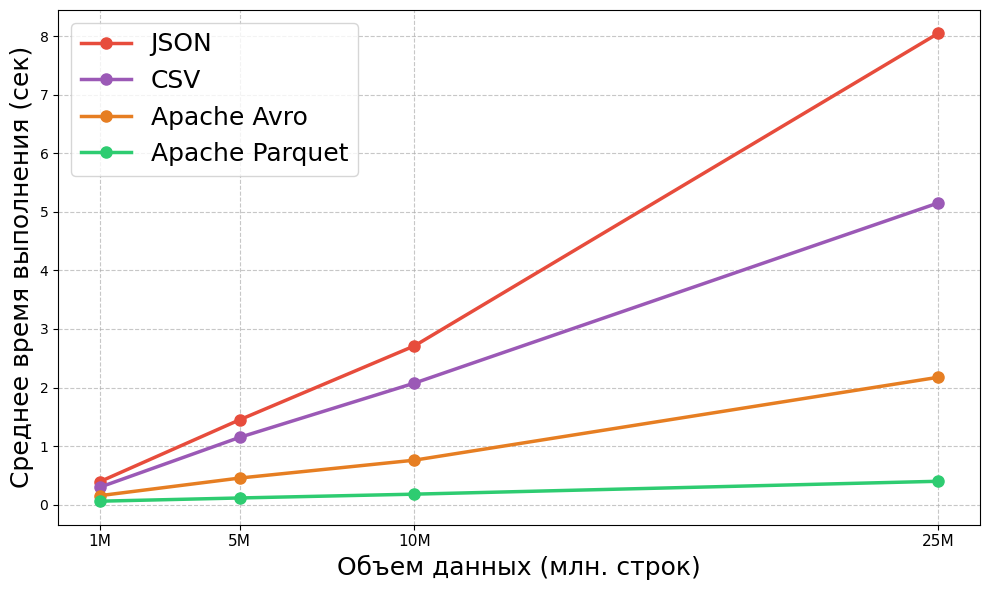

In [18]:
import matplotlib.pyplot as plt

volumes = [1, 5, 10, 25] 

filter_json = [0.32, 1.32, 2.52, 7.55]
filter_csv = [0.25, 1.05, 1.95, 4.80] # ВСТАВЬ СВОИ ДАННЫЕ
filter_avro = [0.15, 0.41, 0.77, 2.20]
filter_parquet = [0.05, 0.07, 0.11, 0.23]

agg_json = [0.47, 1.58, 2.90, 8.54]
agg_csv = [0.35, 1.25, 2.20, 5.50] # ВСТАВЬ СВОИ ДАННЫЕ
agg_avro = [0.16, 0.50, 0.75, 2.15]
agg_parquet = [0.07, 0.16, 0.25, 0.57]

avg_json = [(f + a) / 2 for f, a in zip(filter_json, agg_json)]
avg_csv = [(f + a) / 2 for f, a in zip(filter_csv, agg_csv)]
avg_avro = [(f + a) / 2 for f, a in zip(filter_avro, agg_avro)]
avg_parquet = [(f + a) / 2 for f, a in zip(filter_parquet, agg_parquet)]

plt.figure(figsize=(10, 6))

colors = {'JSON': '#e74c3c', 'CSV': '#9b59b6', 'Avro': '#e67e22', 'Parquet': '#2ecc71'}
markers = {'JSON': 'o', 'CSV': 'o', 'Avro': 'o', 'Parquet': 'o'}

plt.plot(volumes, avg_json, marker=markers['JSON'], color=colors['JSON'], linewidth=2.5, markersize=8, label='JSON')
plt.plot(volumes, avg_csv, marker=markers['CSV'], color=colors['CSV'], linewidth=2.5, markersize=8, label='CSV')
plt.plot(volumes, avg_avro, marker=markers['Avro'], color=colors['Avro'], linewidth=2.5, markersize=8, label='Apache Avro')
plt.plot(volumes, avg_parquet, marker=markers['Parquet'], color=colors['Parquet'], linewidth=2.5, markersize=8, label='Apache Parquet')

plt.xlabel('Объем данных (млн. строк)', fontsize=18)
plt.ylabel('Среднее время выполнения (сек)', fontsize=18)
plt.xticks(volumes, [f"{v}M" for v in volumes], fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=18, loc='upper left')

plt.tight_layout()
plt.savefig('average_performance_degradation.png', dpi=300, bbox_inches='tight')
plt.show()

Колоночная диаграмма успешно сохранена как 'storage_bar_chart.png'


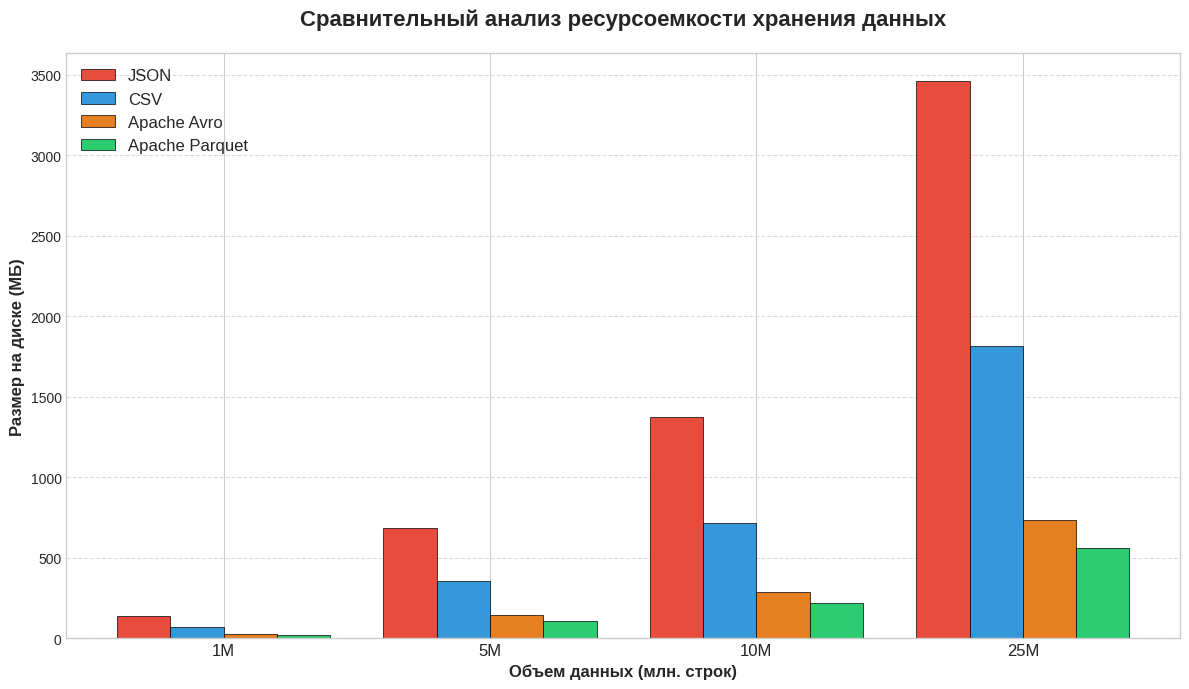

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Наши данные из таблицы
labels = ['1M', '5M', '10M', '25M']
json_sizes = [135.18, 684.37, 1370.85, 3458.93]
csv_sizes = [69.37, 355.35, 712.82, 1813.84]
avro_sizes = [26.98, 142.15, 287.81, 732.70]
parquet_sizes = [20.79, 108.59, 219.17, 559.41]

# 2. Настройка позиций столбцов
x = np.arange(len(labels))  # Расположение групп (0, 1, 2, 3)
width = 0.2  # Ширина одного столбца

# 3. Создаем график
fig, ax = plt.subplots(figsize=(12, 7))

# Строим столбцы со смещением от центра (x), чтобы они стояли рядом
rects1 = ax.bar(x - width*1.5, json_sizes, width, label='JSON', color='#e74c3c', edgecolor='black', linewidth=0.5)
rects2 = ax.bar(x - width*0.5, csv_sizes, width, label='CSV', color='#3498db', edgecolor='black', linewidth=0.5)
rects3 = ax.bar(x + width*0.5, avro_sizes, width, label='Apache Avro', color='#e67e22', edgecolor='black', linewidth=0.5)
rects4 = ax.bar(x + width*1.5, parquet_sizes, width, label='Apache Parquet', color='#2ecc71', edgecolor='black', linewidth=0.5)

# 4. Оформление графика
ax.set_ylabel('Размер на диске (МБ)', fontsize=12, fontweight='bold')
ax.set_xlabel('Объем данных (млн. строк)', fontsize=12, fontweight='bold')
ax.set_title('Сравнительный анализ ресурсоемкости хранения данных', fontsize=16, pad=20, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)

# Добавляем горизонтальную сетку для удобства сравнения высоты столбцов
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Легенда
ax.legend(fontsize=12, loc='upper left')

# 5. Сохранение и вывод
fig.tight_layout()
plt.savefig('storage_bar_chart.png', dpi=300, bbox_inches='tight')
print("Колоночная диаграмма успешно сохранена как 'storage_bar_chart.png'")

plt.show()